MNIST Dataset Loaded
Training samples: 10000
Testing samples: 1000

========== TRAINING SINGLE-LAYER RBM ==========
Epoch 1/5 | Reconstruction Error: 0.1171
Epoch 2/5 | Reconstruction Error: 0.0911
Epoch 3/5 | Reconstruction Error: 0.0866
Epoch 4/5 | Reconstruction Error: 0.0821
Epoch 5/5 | Reconstruction Error: 0.0772

========== TRAINING RBM LAYER 1 ==========
Epoch 1/5 | Reconstruction Error: 0.1172
Epoch 2/5 | Reconstruction Error: 0.0911
Epoch 3/5 | Reconstruction Error: 0.0865
Epoch 4/5 | Reconstruction Error: 0.0820
Epoch 5/5 | Reconstruction Error: 0.0769

========== TRAINING RBM LAYER 2 ==========
Epoch 1/5 | Reconstruction Error: 0.0545
Epoch 2/5 | Reconstruction Error: 0.0536
Epoch 3/5 | Reconstruction Error: 0.0530
Epoch 4/5 | Reconstruction Error: 0.0513
Epoch 5/5 | Reconstruction Error: 0.0468

Visualizing learned filters


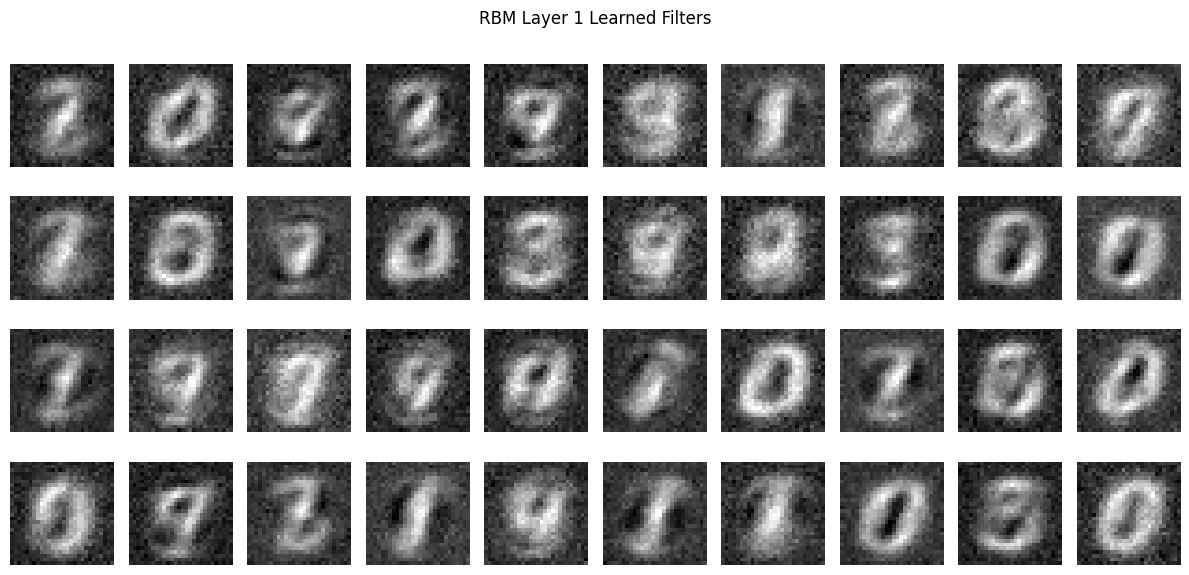

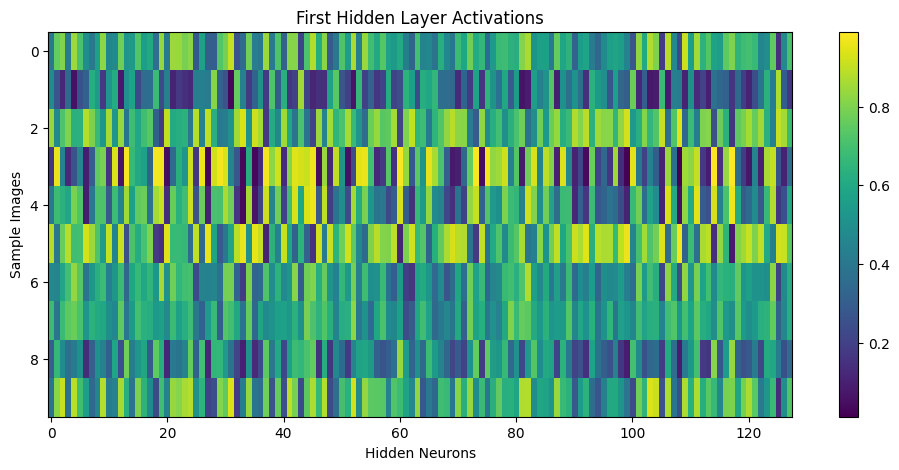

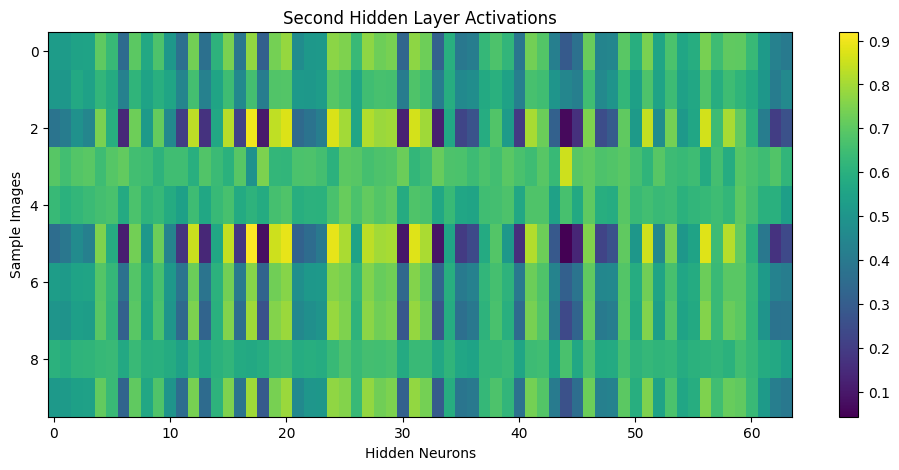


========== RECONSTRUCTION RESULTS ==========
Single RBM MSE        : 0.07429
Hierarchical RBM MSE   : 0.08324


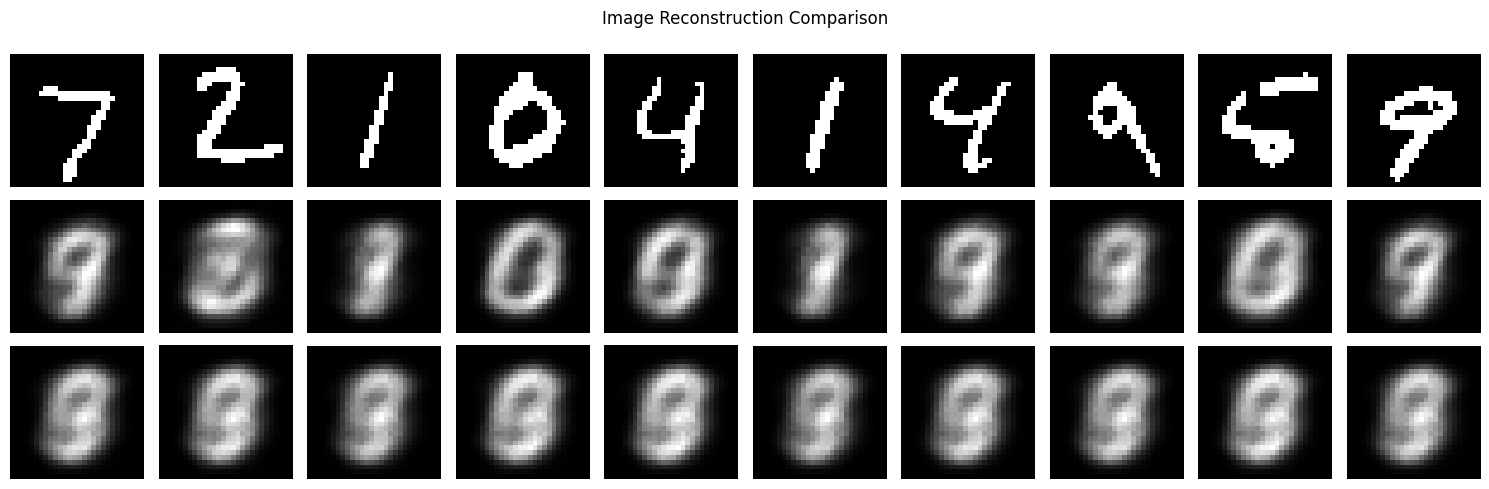

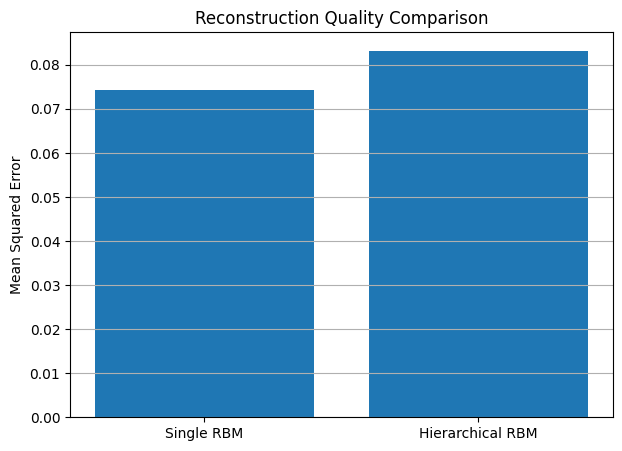

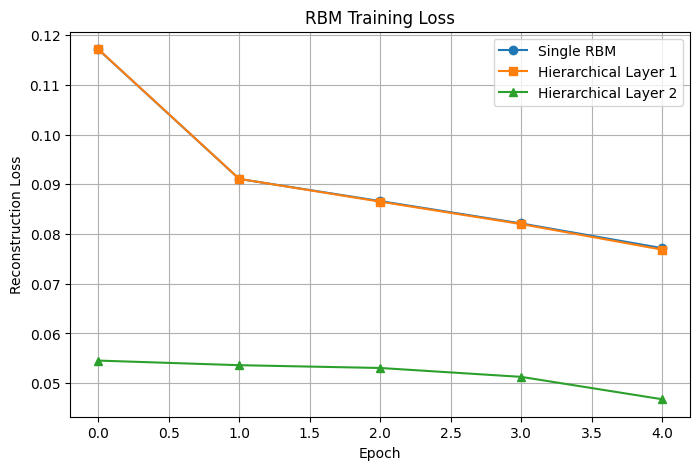


Generating samples using Gibbs sampling


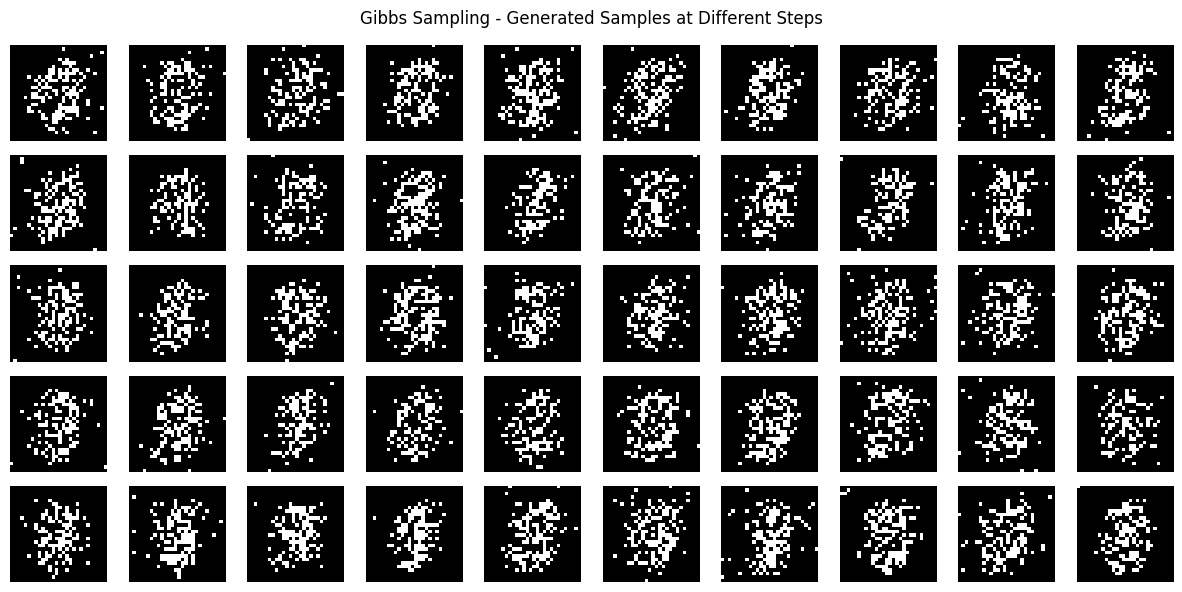


EXPERIMENT 28 COMPLETED SUCCESSFULLY
Single RBM Reconstruction MSE: 0.07429
Hierarchical RBM MSE: 0.08324
Single RBM achieved lower reconstruction error in this run.


In [17]:

# EXPERIMENT 28
# DEEP BOLTZMANN MACHINE / CONVOLUTIONAL BOLTZMANN MACHINE SIMULATION
# Stacked RBM approximation using MNIST
# Complete Google Colab code - Single cell

!pip -q install numpy matplotlib tensorflow scikit-learn

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

np.random.seed(42)
tf.random.set_seed(42)

# ==========================================================
# 1. LOAD MNIST DATASET
# ==========================================================
(x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Binarize images for RBM
x_train = (x_train > 0.5).astype(np.float32)
x_test = (x_test > 0.5).astype(np.float32)

x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

# Use a subset to make Colab training faster
train_data = x_train[:10000]
test_data = x_test[:1000]

print("MNIST Dataset Loaded")
print("Training samples:", train_data.shape[0])
print("Testing samples:", test_data.shape[0])

# ==========================================================
# 2. RBM IMPLEMENTATION
# ==========================================================
class RBM:
    def __init__(self, n_visible, n_hidden, learning_rate=0.01):
        self.n_visible = n_visible
        self.n_hidden = n_hidden
        self.lr = learning_rate

        self.W = np.random.normal(
            0, 0.01, (n_visible, n_hidden)
        ).astype(np.float32)

        self.visible_bias = np.zeros(n_visible, dtype=np.float32)
        self.hidden_bias = np.zeros(n_hidden, dtype=np.float32)

    def sigmoid(self, x):
        x = np.clip(x, -30, 30)
        return 1.0 / (1.0 + np.exp(-x))

    def hidden_prob(self, visible):
        return self.sigmoid(visible @ self.W + self.hidden_bias)

    def visible_prob(self, hidden):
        return self.sigmoid(hidden @ self.W.T + self.visible_bias)

    def sample(self, probabilities):
        return (
            np.random.rand(*probabilities.shape) < probabilities
        ).astype(np.float32)

    def train_batch(self, batch, k=1):
        # Positive phase
        positive_hidden_prob = self.hidden_prob(batch)
        positive_hidden_sample = self.sample(positive_hidden_prob)

        # Gibbs sampling / negative phase
        hidden_sample = positive_hidden_sample

        for _ in range(k):
            visible_prob = self.visible_prob(hidden_sample)
            negative_visible_sample = self.sample(visible_prob)

            negative_hidden_prob = self.hidden_prob(
                negative_visible_sample
            )
            hidden_sample = self.sample(negative_hidden_prob)

        # Contrastive Divergence update
        batch_size = batch.shape[0]

        self.W += self.lr * (
            batch.T @ positive_hidden_prob
            - negative_visible_sample.T @ negative_hidden_prob
        ) / batch_size

        self.visible_bias += self.lr * np.mean(
            batch - negative_visible_sample, axis=0
        )

        self.hidden_bias += self.lr * np.mean(
            positive_hidden_prob - negative_hidden_prob, axis=0
        )

        reconstruction = self.visible_prob(positive_hidden_prob)
        loss = np.mean((batch - reconstruction) ** 2)

        return loss

    def hidden_prob(self, visible):
        return self.sigmoid(visible @ self.W + self.hidden_bias)

    def visible_prob(self, hidden):
        return self.sigmoid(hidden @ self.W.T + self.visible_bias)

    def train(self, data, epochs=5, batch_size=128, k=1):
        history = []

        for epoch in range(epochs):
            indices = np.random.permutation(len(data))
            epoch_losses = []

            for start in range(0, len(data), batch_size):
                batch_indices = indices[start:start+batch_size]
                batch = data[batch_indices]

                loss = self.train_batch(batch, k)
                epoch_losses.append(loss)

            avg_loss = np.mean(epoch_losses)
            history.append(avg_loss)

            print(
                f"Epoch {epoch+1}/{epochs} | "
                f"Reconstruction Error: {avg_loss:.4f}"
            )

        return history

# ==========================================================
# 3. TRAIN SINGLE-LAYER RBM (BASELINE)
# ==========================================================
print("\n========== TRAINING SINGLE-LAYER RBM ==========")

single_rbm = RBM(
    n_visible=784,
    n_hidden=128,
    learning_rate=0.01
)

single_history = single_rbm.train(
    train_data,
    epochs=5,
    batch_size=128,
    k=1
)

# ==========================================================
# 4. TRAIN FIRST HIDDEN LAYER OF HIERARCHICAL RBM
# ==========================================================
print("\n========== TRAINING RBM LAYER 1 ==========")

rbm1 = RBM(
    n_visible=784,
    n_hidden=128,
    learning_rate=0.01
)

rbm1_history = rbm1.train(
    train_data,
    epochs=5,
    batch_size=128,
    k=1
)

# Extract first hidden representation
hidden1_train = rbm1.hidden_prob(train_data)

# ==========================================================
# 5. TRAIN SECOND HIDDEN LAYER
# ==========================================================
print("\n========== TRAINING RBM LAYER 2 ==========")

rbm2 = RBM(
    n_visible=128,
    n_hidden=64,
    learning_rate=0.01
)

rbm2_history = rbm2.train(
    hidden1_train,
    epochs=5,
    batch_size=128,
    k=1
)

# ==========================================================
# 6. VISUALIZE FIRST LAYER FILTERS
# ==========================================================
print("\nVisualizing learned filters")

filters = rbm1.W.T[:40]

fig, axes = plt.subplots(4, 10, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(filters[i].reshape(28, 28), cmap="gray")
    ax.axis("off")

plt.suptitle("RBM Layer 1 Learned Filters")
plt.tight_layout()
plt.show()

# ==========================================================
# 7. VISUALIZE HIDDEN ACTIVATIONS
# ==========================================================
sample_images = test_data[:10]

hidden_activations1 = rbm1.hidden_prob(sample_images)
hidden_activations2 = rbm2.hidden_prob(hidden_activations1)

plt.figure(figsize=(12, 5))
plt.imshow(hidden_activations1, aspect="auto", cmap="viridis")
plt.colorbar()
plt.title("First Hidden Layer Activations")
plt.xlabel("Hidden Neurons")
plt.ylabel("Sample Images")
plt.show()

plt.figure(figsize=(12, 5))
plt.imshow(hidden_activations2, aspect="auto", cmap="viridis")
plt.colorbar()
plt.title("Second Hidden Layer Activations")
plt.xlabel("Hidden Neurons")
plt.ylabel("Sample Images")
plt.show()

# ==========================================================
# 8. RECONSTRUCTION USING SINGLE RBM
# ==========================================================
single_hidden = single_rbm.hidden_prob(test_data)
single_reconstruction = single_rbm.visible_prob(single_hidden)

# ==========================================================
# 9. RECONSTRUCTION USING HIERARCHICAL RBM
# ==========================================================
hier_hidden1 = rbm1.hidden_prob(test_data)
hier_hidden2 = rbm2.hidden_prob(hier_hidden1)

# Decode through second layer
decoded_hidden1 = rbm2.visible_prob(hier_hidden2)

# Decode through first layer
hier_reconstruction = rbm1.visible_prob(decoded_hidden1)

# ==========================================================
# 10. COMPUTE RECONSTRUCTION ERRORS
# ==========================================================
single_mse = np.mean((test_data - single_reconstruction) ** 2)
hier_mse = np.mean((test_data - hier_reconstruction) ** 2)

print("\n========== RECONSTRUCTION RESULTS ==========")
print(f"Single RBM MSE        : {single_mse:.5f}")
print(f"Hierarchical RBM MSE   : {hier_mse:.5f}")

# ==========================================================
# 11. ORIGINAL VS RECONSTRUCTED IMAGE
# ==========================================================
num_images = 10

fig, axes = plt.subplots(3, num_images, figsize=(15, 5))

for i in range(num_images):
    # Original
    axes[0, i].imshow(test_data[i].reshape(28, 28), cmap="gray")
    axes[0, i].axis("off")

    # Single RBM reconstruction
    axes[1, i].imshow(
        single_reconstruction[i].reshape(28, 28), cmap="gray"
    )
    axes[1, i].axis("off")

    # Hierarchical reconstruction
    axes[2, i].imshow(
        hier_reconstruction[i].reshape(28, 28), cmap="gray"
    )
    axes[2, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=12)
axes[1, 0].set_ylabel("Single RBM", fontsize=12)
axes[2, 0].set_ylabel("Hierarchical", fontsize=12)

plt.suptitle("Image Reconstruction Comparison")
plt.tight_layout()
plt.show()

# ==========================================================
# 12. RECONSTRUCTION ERROR COMPARISON
# ==========================================================
plt.figure(figsize=(7, 5))

plt.bar(
    ["Single RBM", "Hierarchical RBM"],
    [single_mse, hier_mse]
)

plt.ylabel("Mean Squared Error")
plt.title("Reconstruction Quality Comparison")
plt.grid(axis="y")
plt.show()

# ==========================================================
# 13. TRAINING LOSS COMPARISON
# ==========================================================
plt.figure(figsize=(8, 5))

plt.plot(single_history, marker="o", label="Single RBM")
plt.plot(rbm1_history, marker="s", label="Hierarchical Layer 1")
plt.plot(rbm2_history, marker="^", label="Hierarchical Layer 2")

plt.xlabel("Epoch")
plt.ylabel("Reconstruction Loss")
plt.title("RBM Training Loss")
plt.legend()
plt.grid()
plt.show()

# ==========================================================
# 14. GENERATE NEW SAMPLES USING GIBBS SAMPLING
# ==========================================================
print("\nGenerating samples using Gibbs sampling")

# Start with random hidden states
generated_hidden2 = np.random.binomial(
    1, 0.5, size=(10, 64)
).astype(np.float32)

generated_images = []

# Gibbs sampling steps
for step in range(5):
    # Layer 2 -> Layer 1
    generated_hidden1 = rbm2.visible_prob(generated_hidden2)
    generated_hidden1 = rbm1.sample(generated_hidden1)

    # Layer 1 -> Visible
    generated_visible = rbm1.visible_prob(generated_hidden1)
    generated_visible = rbm1.sample(generated_visible)

    # Visible -> Layer 1
    generated_hidden1_prob = rbm1.hidden_prob(generated_visible)
    generated_hidden1 = rbm1.sample(generated_hidden1_prob)

    # Layer 1 -> Layer 2
    generated_hidden2_prob = rbm2.hidden_prob(generated_hidden1)
    generated_hidden2 = rbm2.sample(generated_hidden2_prob)

    generated_images.append(generated_visible.copy())

# ==========================================================
# 15. VISUALIZE GENERATED SAMPLES
# ==========================================================
fig, axes = plt.subplots(5, 10, figsize=(12, 6))

for row in range(5):
    for col in range(10):
        axes[row, col].imshow(
            generated_images[row][col].reshape(28, 28),
            cmap="gray"
        )
        axes[row, col].axis("off")

plt.suptitle("Gibbs Sampling - Generated Samples at Different Steps")
plt.tight_layout()
plt.show()

# ==========================================================
# 16. FINAL RESULT
# ==========================================================
print("\n==============================================")
print("EXPERIMENT 28 COMPLETED SUCCESSFULLY")
print("==============================================")
print("Single RBM Reconstruction MSE:", round(single_mse, 5))
print("Hierarchical RBM MSE:", round(hier_mse, 5))

if hier_mse < single_mse:
    print("Hierarchical RBM achieved lower reconstruction error.")
else:
    print("Single RBM achieved lower reconstruction error in this run.")
